<a href="https://colab.research.google.com/github/VETTOORLIJO/DS_VettoorLijo/blob/master/ML_Assign5_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Clustering Algorithms

1. Centroid-Based
*   K-Means
2. Density-Based
*   DBSCAN,HDBSCAN
3. Hierarchical
*    Agglomerative,Divisive
4. Distribution-Based
* Gaussian Mixture Model (GMM)


In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris

In [31]:
iris_df= load_iris()
print(iris_df.keys())

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])


In [32]:
print(iris_df.data)
print(iris_df.target)
print(iris_df.feature_names)
print(iris_df.target_names)

#print(iris_df.DESCR)
#print(iris_df.frame)
#print(iris_df.filename)

[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]
 [5.4 3.9 1.7 0.4]
 [4.6 3.4 1.4 0.3]
 [5.  3.4 1.5 0.2]
 [4.4 2.9 1.4 0.2]
 [4.9 3.1 1.5 0.1]
 [5.4 3.7 1.5 0.2]
 [4.8 3.4 1.6 0.2]
 [4.8 3.  1.4 0.1]
 [4.3 3.  1.1 0.1]
 [5.8 4.  1.2 0.2]
 [5.7 4.4 1.5 0.4]
 [5.4 3.9 1.3 0.4]
 [5.1 3.5 1.4 0.3]
 [5.7 3.8 1.7 0.3]
 [5.1 3.8 1.5 0.3]
 [5.4 3.4 1.7 0.2]
 [5.1 3.7 1.5 0.4]
 [4.6 3.6 1.  0.2]
 [5.1 3.3 1.7 0.5]
 [4.8 3.4 1.9 0.2]
 [5.  3.  1.6 0.2]
 [5.  3.4 1.6 0.4]
 [5.2 3.5 1.5 0.2]
 [5.2 3.4 1.4 0.2]
 [4.7 3.2 1.6 0.2]
 [4.8 3.1 1.6 0.2]
 [5.4 3.4 1.5 0.4]
 [5.2 4.1 1.5 0.1]
 [5.5 4.2 1.4 0.2]
 [4.9 3.1 1.5 0.2]
 [5.  3.2 1.2 0.2]
 [5.5 3.5 1.3 0.2]
 [4.9 3.6 1.4 0.1]
 [4.4 3.  1.3 0.2]
 [5.1 3.4 1.5 0.2]
 [5.  3.5 1.3 0.3]
 [4.5 2.3 1.3 0.3]
 [4.4 3.2 1.3 0.2]
 [5.  3.5 1.6 0.6]
 [5.1 3.8 1.9 0.4]
 [4.8 3.  1.4 0.3]
 [5.1 3.8 1.6 0.2]
 [4.6 3.2 1.4 0.2]
 [5.3 3.7 1.5 0.2]
 [5.  3.3 1.4 0.2]
 [7.  3.2 4.7 1.4]
 [6.4 3.2 4.5 1.5]
 [6.9 3.1 4.

In [33]:
df = pd.DataFrame(iris_df.data, columns=iris_df.feature_names)
df["flower_type"] = iris_df.target
print(iris_df.target_names)
df.head(5)

['setosa' 'versicolor' 'virginica']


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),flower_type
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [34]:
df.isna().sum()
df.duplicated().sum()
df.dtypes
df.isnull().sum()

,0
sepal length (cm),0
sepal width (cm),0
petal length (cm),0
petal width (cm),0
flower_type,0


In [35]:
## Feature Scaling
#Scaling is critical in distance-based.
from sklearn.preprocessing import StandardScaler

In [36]:
scaler = StandardScaler()
scaled = scaler.fit_transform(df.drop("flower_type", axis=1))
# scaled data change to df
scaled_df = pd.DataFrame(scaled, columns=df.drop("flower_type", axis=1).columns)
scaled_df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.900681,1.019004,-1.340227,-1.315444
1,-1.143017,-0.131979,-1.340227,-1.315444
2,-1.385353,0.328414,-1.397064,-1.315444
3,-1.506521,0.098217,-1.283389,-1.315444
4,-1.021849,1.249201,-1.340227,-1.315444


* centroid-based clustering algorithm

find the K value. K-Means is a centroid-based clustering algorithm that groups similar data points by repeatedly assigning them to the nearest centroid and updating the centroid positions until the clusters become stable.

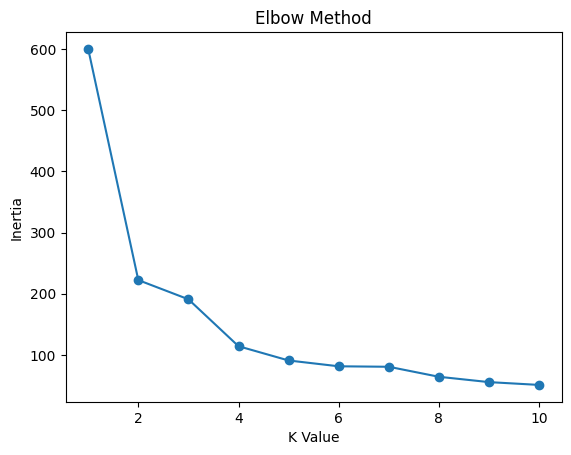

In [37]:
# Elbow Method in graph
from sklearn.cluster import KMeans
inertia = []
for k in range(1,11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(scaled)
    inertia.append(kmeans.inertia_)
plt.plot(range(1,11), inertia, marker="o")
plt.title("Elbow Method")
plt.xlabel("K Value")
plt.ylabel("Inertia")
plt.show()


In [38]:
# silhouette_score method
from sklearn.metrics import silhouette_score

In [39]:
scores =[]

In [40]:
for k in range(2,11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(scaled)
    score = silhouette_score(scaled, labels)
    scores.append(score)
    print(score)

0.5817500491982808
0.4798814508199817
0.3850454053045392
0.34503345350274617
0.3339432304006177
0.2664290993719981
0.34162906041313373
0.32439914389835445
0.33540615043919825


ScoreMeaning    
* 1Excellent clustering
* 0.7 - 1.0Very good
* 0.5 - 0.7Good
* 0.25 - 0.5
* Weak but usable< 0.25 Poor clusteringNegativeWrong clustering

In [41]:
kmeans = KMeans(n_clusters=3, random_state=42)
cluster = kmeans.fit_predict(scaled)
df["cluster"] = cluster
df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),flower_type,cluster
0,5.1,3.5,1.4,0.2,0,1
1,4.9,3.0,1.4,0.2,0,2
2,4.7,3.2,1.3,0.2,0,2
3,4.6,3.1,1.5,0.2,0,2
4,5.0,3.6,1.4,0.2,0,1
...,...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2,0
146,6.3,2.5,5.0,1.9,2,0
147,6.5,3.0,5.2,2.0,2,0
148,6.2,3.4,5.4,2.3,2,0


In [42]:
summary = df.groupby("cluster")["flower_type"].sum()
summary

,flower_type
cluster,
0,146
1,0
2,4


In [43]:
# kmeans = KMeans(n_clusters=5, random_state=42)
# cluster = kmeans.fit_predict(scaled)
# df["cluster"] = cluster
# df
# summary = df.groupby("cluster")["flower_type"].sum()
# summary

In [44]:
from sklearn.decomposition import PCA
pca = PCA(n_components=3)
pca.fit(scaled)
scaled_pca = pca.transform(scaled)


Explain why KMeans clustering might be suitable for the Iris dataset.
* K-Means is suitable for the Iris dataset because it contains numerical data with naturally occurring groups. The algorithm can separate similar flowers into clusters based on their measurements.

In [45]:
def plot_3d(scaled_pca):
    fig = plt.figure(figsize=(10,8))
    ax = fig.add_subplot(111, projection='3d')
    scatter = ax.scatter(
        scaled_pca[:,0],
        scaled_pca[:,1],
        scaled_pca[:,2],
        c=df['cluster'],
        cmap='Set1'
    )

    ax.set_xlabel('PCA 1')
    ax.set_ylabel('PCA 2')
    ax.set_zlabel('PCA 3')

    plt.colorbar(scatter, label='Cluster')

    plt.show()

**Apply KMeans clustering to the preprocessed Iris dataset and visualize the clusters.**

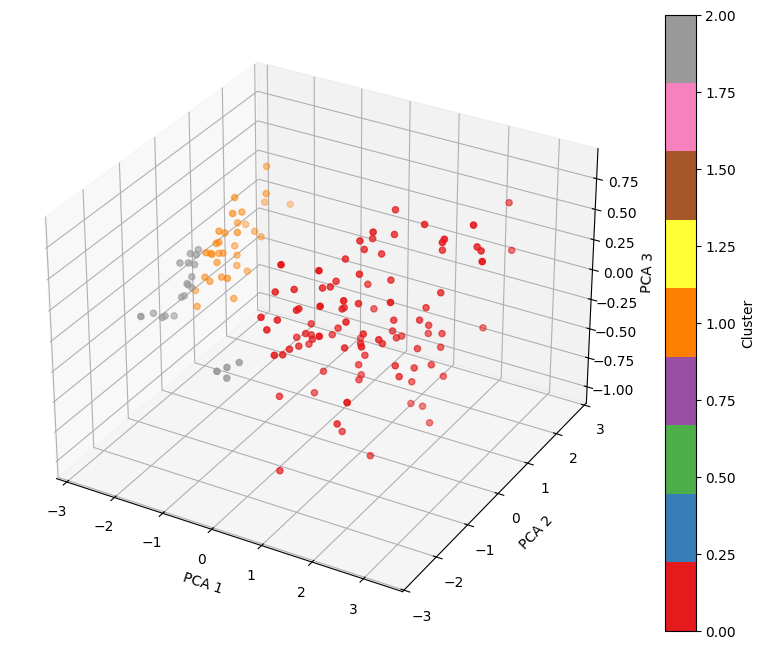

In [46]:
plot_3d(scaled_pca)


**Hierarchical Clustering (Agglomerative )**

In [47]:
# Hierarchical Clustering is an unsupervised learning algorithm that groups similar data points by repeatedly merging the closest clusters, creating a tree-like structure called a dendrogram.

In [48]:
#Tuning Parameter
# 1) linkage='single'
# 2) linkage='complete'
# 3) linkage='average'
# 4) linkage='ward'   Most Common

In [49]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

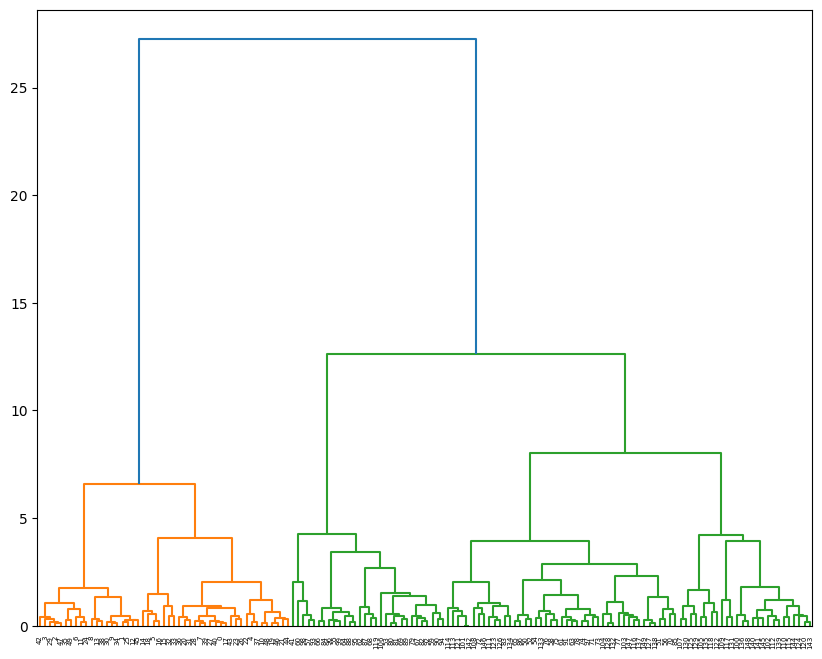

In [50]:
linked= linkage(scaled, method='ward')
plt.figure(figsize=(10,8))
dendrogram(linked)
plt.show()
#

Bigest line sujest 2 cluster and silhouette_score also sujest 2 , but we already know Iris contains 3 diffrent items

In [51]:
agglomerative_model = AgglomerativeClustering(n_clusters=3)
agglomerative_model.fit(scaled)
df['cluster'] = agglomerative_model.labels_
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),flower_type,cluster
0,5.1,3.5,1.4,0.2,0,1
1,4.9,3.0,1.4,0.2,0,1
2,4.7,3.2,1.3,0.2,0,1
3,4.6,3.1,1.5,0.2,0,1
4,5.0,3.6,1.4,0.2,0,1


Hierarchical Clustering is suitable for the Iris dataset because the dataset contains numerical measurements that naturally form groups based on flower characteristics. The algorithm can identify these similarities by calculating distances between flowers and gradually building clusters. Since the Iris dataset is relatively small, Hierarchical Clustering is computationally efficient

In [52]:
agglomerative_model = AgglomerativeClustering(n_clusters=3, linkage='complete')  #  complete used
agglomerative_model.fit(scaled)
df['cluster'] = agglomerative_model.labels_
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),flower_type,cluster
0,5.1,3.5,1.4,0.2,0,1
1,4.9,3.0,1.4,0.2,0,1
2,4.7,3.2,1.3,0.2,0,1
3,4.6,3.1,1.5,0.2,0,1
4,5.0,3.6,1.4,0.2,0,1


Apply Hierarchical clustering to the preprocessed Iris dataset and visualize the clusters.

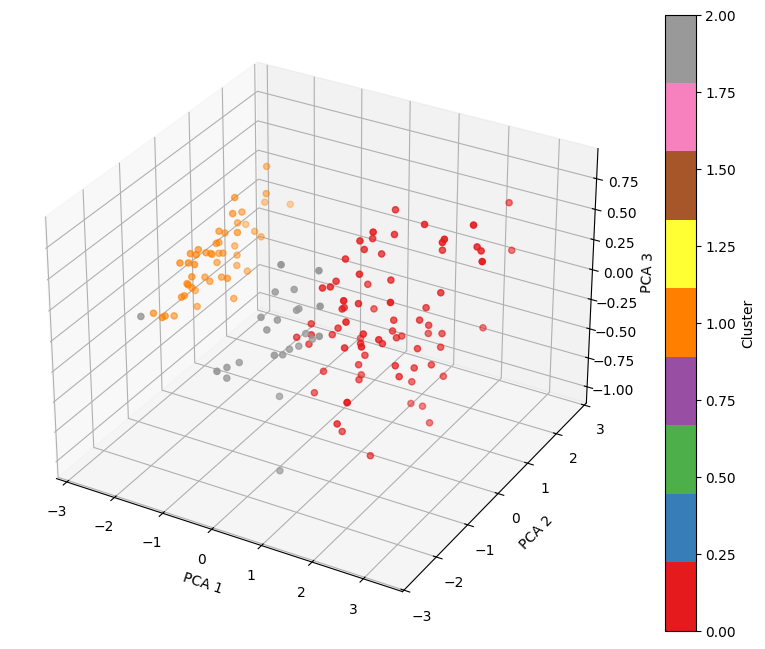

In [53]:
plot_3d(scaled_pca)

In [54]:
import plotly.express as px
import pandas as pd

plot_df = pd.DataFrame({
    'PCA1': scaled_pca[:,0],
    'PCA2': scaled_pca[:,1],
    'PCA3': scaled_pca[:,2],
    'Cluster': df['cluster'].astype(str)
})

fig = px.scatter_3d(
    plot_df,
    x='PCA1',
    y='PCA2',
    z='PCA3',
    color='Cluster',
    title='Agglomerative Clustering (3D PCA)',
    opacity=0.8
)

fig.update_traces(marker=dict(size=5))

fig.show()

DBSCAN

[ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 -1  0  0  0  0  0  0
  0  0  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1 -1  1  1  1  1  1  1  1 -1  1  1
  1  1  1  1  1  1  1  1  1  1  1 -1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1]


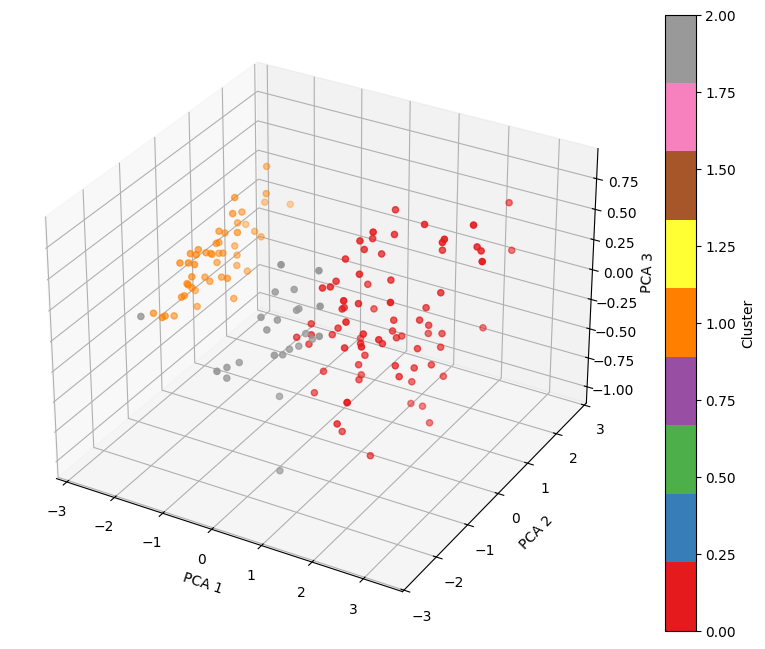

In [55]:
from sklearn.cluster import DBSCAN
dbscan_model = DBSCAN(eps=0.8, min_samples=5 )
clusters = dbscan_model.fit_predict(scaled)
print(clusters)
plot_3d(scaled_pca)

In [56]:
import plotly.express as px
import pandas as pd

plot_df = pd.DataFrame({
    'PCA1': scaled_pca[:,0],
    'PCA2': scaled_pca[:,1],
    'PCA3': scaled_pca[:,2],
    'Cluster': df['cluster'].astype(str)
})

fig = px.scatter_3d(
    plot_df,
    x='PCA1',
    y='PCA2',
    z='PCA3',
    color='Cluster',
    title='DBSCAN',
    opacity=0.8
)

fig.update_traces(marker=dict(size=5))

fig.show()

In [57]:
# Gaussian Mixture Model (GMM)
from sklearn.mixture import GaussianMixture

gmm_model = GaussianMixture(n_components=3,random_state=42)
gmm_model.fit(scaled)
clusters = gmm_model.predict(scaled)
print(clusters)
df['cluster'] = clusters

[1 1 1 1 1 1 1 1 2 1 1 1 1 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 2 1 1 2 2 1 1 1 1 1 1 1 0 0 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0]


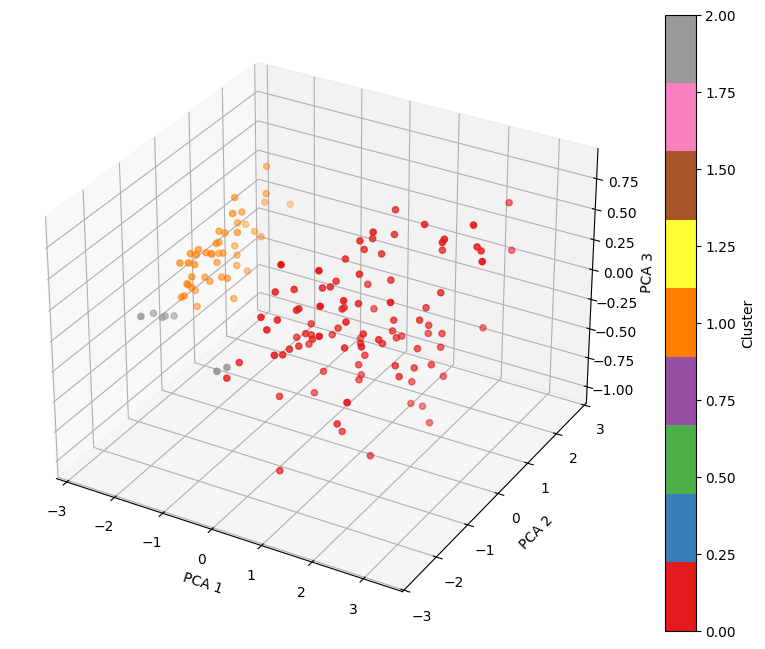

In [58]:
plot_3d(scaled_pca)